# Cuatro noches en Cheté
### Una estimación, un modelo y una comparación temporal

**Pregunta del equipo.** ¿Cuántos *Anopheles* cabe esperar en el total de una visita de cuatro noches por sublocalidad, con 12 horas programadas por noche, en Cheté 1 y Cheté 2? La cifra orienta la planeación del material. El escenario supone que se cumplen las jornadas previstas y que el registro es comparable al histórico.

**Unidad y éxito.** Un registro publicado contiene individuos de una especie. Un `eventID` corresponde aquí a un evento en un sitio. Para valorar la decisión del equipo se suman los dos sitios del mismo año y mes. El modelo aporta si reduce el **error absoluto medio (MAE) del total** frente a la referencia. Un error de 100 equivale a 100 mosquitos de diferencia en el total previsto, en promedio.

**Alcance de esta revisión.** El proyecto original ya mostró los resultados de 2023 durante la exploración. Se reconstruye su evaluación retrospectiva y se conservan los cortes de años. Para una prueba ciega se necesita una campaña cuyos resultados el equipo desconozca al cerrar el modelo. Este cuaderno documenta una propuesta posterior al análisis inicial.

Para ejecutar, use “Ejecutar todo” en Jupyter o Colab. Se necesita Python con pandas, NumPy y Matplotlib. La primera lectura descarga la versión 1.0 del INS. Si se dispone de su archivo `occurrence.txt`, puede colocarse junto al cuaderno y trabajar sin conexión.

## 1. Antes de empacar

La idea de Fermi es multiplicar noches, puestos, horas activas por puesto y capturas por hora y puesto. El documento de contexto describe un borrador con cuatro puestos, actividad del 75 % y una tasa central de 2. Para ese borrador se puede calcular un rango cambiando solo la tasa entre 0,5 y 5, los valores que el equipo había considerado. En sus rangos propuestos, la tasa cambia por un factor de 10, mayor que la variación de puestos, duración o fracción activa.

El cuaderno entregado a revisión usa otro escenario, con seis puestos. Ambos cálculos aparecen aquí para que se pueda identificar en el historial de GitHub cuál se entregó antes de abrir los datos. El rango del primer cálculo expresa incertidumbre en un supuesto.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from io import BytesIO
from pathlib import Path
from urllib.request import urlopen
from zipfile import ZipFile

tasas_hipoteticas = np.array([0.5, 2, 5])
fermi_borrador = 4 * 4 * 6 * 0.75 * tasas_hipoteticas
fermi_cuaderno = 4 * 6 * (3 * 2 + 3 * 1)

print("Borrador de cuatro puestos (bajo, central, alto):", fermi_borrador.astype(int))
print("Escenario de seis puestos del cuaderno:", fermi_cuaderno)

Borrador de cuatro puestos (bajo, central, alto): [ 36 144 360]
Escenario de seis puestos del cuaderno: 216


## 2. Qué mide el registro

La fuente es el archivo Darwin Core v1.0 publicado por el Instituto Nacional de Salud. El estudio comprende enero de 2021 a marzo de 2023, con jornadas habituales de 12 horas y jornadas iniciales de 14. La ficha describe un muestreo dentro y fuera de viviendas. En los registros de Cheté la categoría publicada de hábitat es «En domicilio». Allí faltan el desglose por ambiente, el puesto individual y las horas activas de cada persona. El dato tabulado es un conteo agregado. [Ficha del estudio y descarga, DOI 10.15472/kftrcn, CC BY-NC 4.0](https://ipt.biodiversidad.co/sib/resource?r=ins_mosquiteros_malaria)

**Hoja de campo propuesta.** Una pestaña de turnos registra identificador, fecha, sublocalidad, vivienda, puesto, ambiente, horas de inicio y fin, tiempo efectivo, lluvia y estado del turno. Otra pestaña enlaza cada captura al turno con su hora, especie o identificación pendiente y sexo cuando se conoce. Un turno cerrado con esfuerzo positivo y captura explícita de cero documenta un cero. Un turno sin realizar o con la hoja perdida queda identificado como tal. El archivo publicado reúne ocurrencias positivas en Cheté. Los meses sin registro no permiten conocer el conteo.

El pronóstico describe visitas como las representadas en el archivo. Si quedaron fuera visitas enteras con cero capturas, la previsión para el conjunto de todas las visitas podría quedar alta.

Se trabaja con los dos sitios de Cheté porque son el destino de la visita. Se limita así el número de rondas disponibles y el alcance de la predicción. La lluvia forma parte del escenario del reto y carece de una medición por campaña en esta tabla.

In [2]:
archivo = Path("occurrence.txt")
if archivo.is_file():
    fuente = pd.read_csv(archivo, sep="\t", low_memory=False)
else:
    url = "https://ipt.biodiversidad.co/sib/archive.do?r=ins_mosquiteros_malaria&v=1.0"
    with urlopen(url, timeout=30) as respuesta, ZipFile(BytesIO(respuesta.read())) as paquete:
        with paquete.open("occurrence.txt") as tabla:
            fuente = pd.read_csv(tabla, sep="\t", low_memory=False)

registros = fuente.loc[fuente["municipality"].eq("Timbiquí") & fuente["locality"].eq("Cheté")].copy()
registros["sitio"] = registros["verbatimLocality"].map({"Chete 1": "Cheté 1", "Chete 2": "Cheté 2"})
assert registros["occurrenceID"].is_unique and registros["eventID"].notna().all()
assert registros["sitio"].notna().all() and registros["individualCount"].gt(0).all()

esfuerzo = registros["samplingEffort"].str.extract(r"^(\d+) h por noche, (\d+) noches?$")
assert esfuerzo.notna().all().all(), "Hay una forma de esfuerzo sin interpretar"
registros["noches"] = esfuerzo[1].astype(int)
registros["horas"] = esfuerzo[0].astype(int) * registros["noches"]

registros["mes_publicado"] = pd.to_datetime(registros["eventDate"].str[:10]).dt.to_period("M")
por_evento = registros.groupby("eventID")
assert por_evento["mes_publicado"].nunique().eq(1).all() and por_evento["sitio"].nunique().eq(1).all()
registros["mes_inferido"] = registros["mes_publicado"].isna()
registros["mes"] = por_evento["mes_publicado"].transform("first")
print("Registros con mes recuperado de otra fila del mismo evento:", registros["mes_inferido"].sum())

Registros con mes recuperado de otra fila del mismo evento: 1


**Una sola tabla por evento.** Se suman los individuos y se toma la duración de la fila con mayor esfuerzo. Así se contabiliza una sola vez una jornada que varias especies pueden compartir. Dos eventos tienen duraciones distintas entre sus filas. Se conservan marcados y se comprueba cuánto cambia la proyección al excluirlos. Se usa «hora de evento» como una aproximación a la exposición. El archivo tampoco identifica si las horas realizadas coincidieron con las programadas.

Para la evaluación se emparejan las dos visitas del mismo año y mes. Los intervalos de fechas de los sitios pueden diferir. Este emparejamiento aproxima la escala de una visita conjunta y permite mantener juntas las dos mediciones de cada ronda.

In [3]:
eventos = por_evento.agg(
    mes=("mes", "first"), sitio=("sitio", "first"),
    total=("individualCount", "sum"), esfuerzos_distintos=("horas", "nunique")
)
fila_mayor = registros.loc[por_evento["horas"].idxmax(), ["eventID", "horas", "noches"]]
eventos = eventos.join(fila_mayor.set_index("eventID")).sort_values(["mes", "sitio"])
assert eventos["total"].sum() == registros["individualCount"].sum() and eventos["horas"].gt(0).all()
assert not eventos.duplicated(["mes", "sitio"]).any()
assert eventos.groupby("mes")["sitio"].nunique().eq(2).all()

desarrollo = registros.loc[registros["mes"].dt.year.lt(2023)]
print("Eventos con varias duraciones:", eventos.index[eventos["esfuerzos_distintos"].gt(1)].tolist())
print("Eventos de desarrollo por año:")
print(eventos.loc[eventos["mes"].dt.year.lt(2023)].groupby(eventos["mes"].dt.year).size())

Eventos con varias duraciones: ['Chete1-01', 'Chete2-01']
Eventos de desarrollo por año:
mes
2021    18
2022    20
dtype: int64


### Hallazgo y prueba de sensibilidad

Se comparan los dos sitios en los mismos meses de 2021–2022 para *An. albimanus*. Una fila por sitio y mes reúne el conteo de la especie y la duración documentada una sola vez. Se repite la comparación usando únicamente meses con la misma duración en ambos sitios.

Para medir la incertidumbre se calcula la diferencia media en cada trimestre representado y se remuestrean esos trimestres completos. Cada trimestre tiene igual peso. El remuestreo conserva los meses y los sitios emparejados dentro del trimestre. Con ocho trimestres y posible asociación entre trimestres, el intervalo es aproximado y se refiere a estos dos sitios.

Todos los pares: Cheté 1 supera a Cheté 2 en 18 de 19 meses
Igual esfuerzo: Cheté 1 supera a Cheté 2 en 10 de 11 meses
Diferencia media entre sitios: 5.08 capturas/h
Intervalo bootstrap del 95 % (trimestres): 3.05 a 6.85


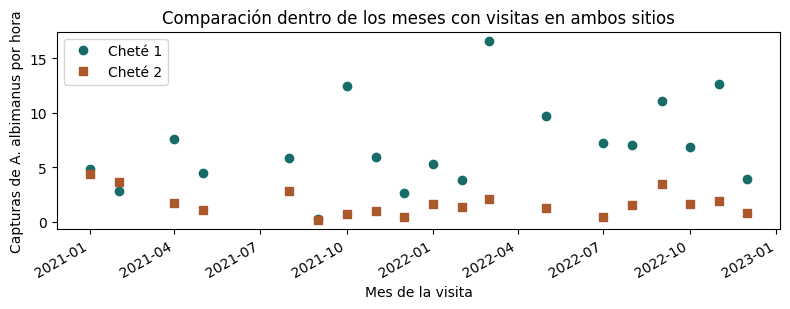

In [4]:
albimanus = desarrollo.loc[desarrollo["scientificName"].eq("Anopheles albimanus")]
por_sitio_mes = albimanus.groupby(["mes", "sitio"])
assert por_sitio_mes["horas"].nunique().eq(1).all()
resumen = por_sitio_mes.agg(capturas=("individualCount", "sum"), horas=("horas", "first"))
tasas = (resumen["capturas"] / resumen["horas"]).unstack().dropna()
horas_pares = resumen["horas"].unstack().loc[tasas.index]
diferencia = tasas["Cheté 1"] - tasas["Cheté 2"]
iguales = horas_pares["Cheté 1"].eq(horas_pares["Cheté 2"])
for nombre, serie in [("Todos los pares", diferencia), ("Igual esfuerzo", diferencia[iguales])]:
    print(f"{nombre}: Cheté 1 supera a Cheté 2 en {serie.gt(0).sum()} de {len(serie)} meses")

trimestres = diferencia.groupby(diferencia.index.asfreq("Q")).mean()
sorteos = np.random.default_rng(42).choice(trimestres, size=(5000, len(trimestres)))
limites = np.quantile(sorteos.mean(axis=1), [0.025, 0.975])
print(f"Diferencia media entre sitios: {trimestres.mean():.2f} capturas/h")
print(f"Intervalo bootstrap del 95 % (trimestres): {limites[0]:.2f} a {limites[1]:.2f}")

ax = tasas.to_timestamp().plot(style=["o", "s"], color=["#176c6a", "#ab592c"], figsize=(8, 3.2))
ax.set(xlabel="Mes de la visita", ylabel="Capturas de A. albimanus por hora", title="Comparación dentro de los meses con visitas en ambos sitios")
ax.legend(title=None)
plt.tight_layout()
plt.show()

## 3. Qué esperar de cuatro noches

Se conservan tres cuentas para que la comparación exigida en el reto sea explícita. Se estiman todas las tasas exclusivamente con años anteriores al de evaluación.

| Método | Cálculo de la predicción |
| --- | --- |
| Fermi revisado | Multiplicar las noches-sitio programadas por las capturas totales históricas divididas entre las noches-sitio históricas. Responde a qué ritmo nocturno conjunto permiten estimar los datos. |
| Referencia histórica | Multiplicar las horas programadas por una tasa común a los dos sitios, calculada como capturas totales divididas entre horas totales. Es la referencia del cuaderno inicial. |
| Modelo por sitio | En cada sitio, multiplicar sus horas programadas por su tasa histórica y sumar ambas predicciones. |

La revisión de Fermi conserva la proporcionalidad con el esfuerzo. Cambia la unidad a una noche de evento en un sitio porque el archivo no permite recuperar todas las horas por puesto del planteamiento inicial. El Fermi revisado y la referencia pueden dar cifras próximas al haber muchas jornadas de 12 horas.

El tercer cálculo reproduce exactamente la predicción central de la regresión de Poisson original. Con un indicador de sitio y el logaritmo de horas como *offset*, la tasa ajustada en cada grupo es la suma de sus capturas dividida entre la suma de sus horas. Se conserva así un modelo de conteos con una fórmula explicable en la sustentación.

In [5]:
metodos = ["Fermi revisado", "Referencia", "Modelo por sitio"]
plan = pd.DataFrame({"sitio": ["Cheté 1", "Cheté 2"], "noches": [4, 4], "horas": [48, 48]})

def predecir(historial, diseno):
    capturas = historial["total"].sum()
    tasa_noche = capturas / historial["noches"].sum()
    tasa_global = capturas / historial["horas"].sum()
    totales_sitio = historial.groupby("sitio")[["total", "horas"]].sum()
    tasas_sitio = totales_sitio["total"] / totales_sitio["horas"]
    return pd.DataFrame({
        "Fermi revisado": diseno["noches"] * tasa_noche,
        "Referencia": diseno["horas"] * tasa_global,
        "Modelo por sitio": diseno["horas"] * diseno["sitio"].map(tasas_sitio)
    }, index=diseno.index)

**Evaluación temporal y rango de predicción.** Primero se entrena con 2021 y se evalúa en 2022. Luego se ajusta con 2021–2022 y se reconstruye la evaluación de 2023. El criterio principal compara el total de los dos sitios en meses con cuatro noches y 48 h registradas por sitio. El pronóstico de ese escenario se fija antes de usar los conteos del año evaluado. Que se pueda comprobar la duración realizada no permite verificar que hubiera sido planificada.

Para poner un rango al pronóstico se lleva cada mes histórico completo al mismo esfuerzo de 48 h por sitio y se suman los dos conteos estandarizados. Los percentiles 5 y 95 de esos totales dan un rango histórico orientativo. Esto mantiene emparejados los dos sitios. Se comprueba cuántos totales posteriores cayeron dentro del rango. La muestra es pequeña y la extrapolación supone proporcionalidad con las horas.

En la tabla de errores, las dos primeras columnas de MAE reproducen el análisis de todas las duraciones bajo la condición de conocer el esfuerzo registrado. La última columna usa solo las visitas comparables con el plan fijo.

In [6]:
errores, bandas, detalle = [], [], []
for anio in (2022, 2023):
    historial = eventos.loc[eventos["mes"].dt.year.lt(anio)]
    prueba = eventos.loc[eventos["mes"].dt.year.eq(anio)]
    total_previsto = predecir(historial, plan).sum()
    estandarizados = (48 * historial["total"] / historial["horas"]).groupby(historial["mes"]).sum()
    bajo, alto = estandarizados.quantile([0.05, 0.95])

    cumple_plan = prueba["noches"].eq(4) & prueba["horas"].eq(48)
    meses_comparables = cumple_plan.groupby(prueba["mes"]).all()
    real = prueba.groupby("mes")["total"].sum().loc[meses_comparables]
    bandas.append([anio, len(estandarizados), bajo, alto, real.between(bajo, alto).sum(), len(real)])
    for mes, total in real.items():
        detalle.append([mes, total, *total_previsto[metodos], bajo, alto])

    con_esfuerzo_registrado = predecir(historial, prueba[["sitio", "horas", "noches"]])
    for metodo in metodos:
        error_sitio = con_esfuerzo_registrado[metodo] - prueba["total"]
        error_conjunto = error_sitio.groupby(prueba["mes"]).sum()
        error_plan = total_previsto[metodo] - real
        errores.append([anio, metodo, error_sitio.abs().mean(), error_conjunto.abs().mean(), error_plan.abs().mean()])

mae = pd.DataFrame(errores, columns=["Año", "Método", "MAE por sitio", "MAE por par mensual", "MAE par de 4 noches"])
rondas = pd.DataFrame(detalle, columns=["Mes", "Observado", *metodos, "P5", "P95"]).set_index("Mes")
intervalos = pd.DataFrame(bandas, columns=["Año", "Meses históricos", "P5", "P95", "Dentro", "Pares evaluados"])
display(mae.round(2), rondas[["Observado", *metodos]].round(2), intervalos.round(2))

,Año,Método,MAE por sitio,MAE por par mensual,MAE par de 4 noches
0,2022,Fermi revisado,128.23,129.49,173.04
1,2022,Referencia,128.35,132.68,176.31
2,2022,Modelo por sitio,73.42,136.19,179.91
3,2023,Fermi revisado,113.46,132.70,132.70
4,2023,Referencia,111.75,128.08,128.08
5,2023,Modelo por sitio,66.59,124.62,124.62


,Observado,Fermi revisado,Referencia,Modelo por sitio
Mes,,,,
2022-10,418,369.89,360.07,349.26
2022-11,720,369.89,360.07,349.26
2022-12,249,369.89,360.07,349.26
2023-01,421,425.37,420.24,409.86
2023-02,277,425.37,420.24,409.86
2023-03,180,425.37,420.24,409.86


,Año,Meses históricos,P5,P95,Dentro,Pares evaluados
0,2022,9,72.27,556.74,2,3
1,2023,19,139.27,737.60,3,3


### La cifra para planear

Para orientar la siguiente visita se conserva el ajuste de 2021–2022 que se evaluó. La cifra central es de unos **410 mosquitos entre las dos sublocalidades**. Los totales usados como contraste provienen de meses en los que las dos visitas tienen el esfuerzo propuesto. La suma por mes equivale a cuatro noches por sitio, sin exigir coincidencia de sus fechas exactas. El modelo reparte mejor el total por sitio que la referencia global. La ganancia para el total es pequeña en 2023 y se invierte en 2022. Es una guía aproximada para dimensionar materiales.

La banda resume la variación histórica de pares completos bajo el esfuerzo estándar. Su cobertura observada se informa en la tabla anterior. Inferir una cobertura futura del 90 % requeriría más campañas independientes.

Predicción por sitio y total (mosquitos):


,Fermi revisado,Referencia,Modelo por sitio
Cheté 1,212.68,210.12,330.02
Cheté 2,212.68,210.12,79.84
Total,425.37,420.24,409.86


Al excluir los dos eventos con esfuerzo ambiguo: 409.98 mosquitos


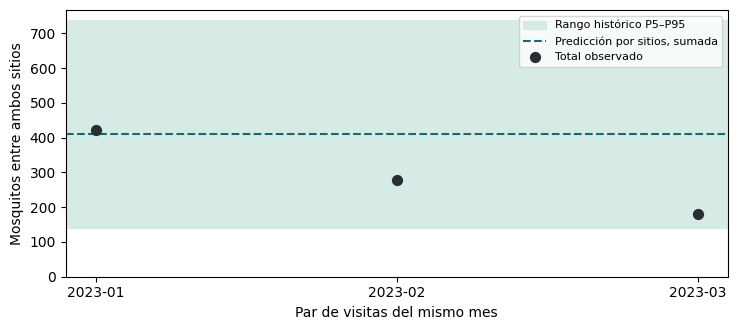

In [7]:
historial_final = eventos.loc[eventos["mes"].dt.year.lt(2023)]
estimacion = predecir(historial_final, plan)
print("Predicción por sitio y total (mosquitos):")
estimacion.index = plan["sitio"]
display(pd.concat([estimacion, estimacion.sum().to_frame("Total").T]).round(2))
sin_ambiguos = historial_final.loc[historial_final["esfuerzos_distintos"].eq(1)]
alternativa = predecir(sin_ambiguos, plan)["Modelo por sitio"].sum()
print(f"Al excluir los dos eventos con esfuerzo ambiguo: {alternativa:.2f} mosquitos")

contraste = rondas.loc[rondas.index.year == 2023]
x = np.arange(len(contraste))
fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.axhspan(contraste["P5"].iloc[0], contraste["P95"].iloc[0], color="#d7ebe6", label="Rango histórico P5–P95")
ax.axhline(estimacion["Modelo por sitio"].sum(), color="#176c6a", linestyle="--", label="Predicción por sitios, sumada")
ax.scatter(x, contraste["Observado"], color="#282e35", s=50, label="Total observado", zorder=3)
ax.set(xticks=x, xticklabels=contraste.index.astype(str), xlabel="Par de visitas del mismo mes", ylabel="Mosquitos entre ambos sitios", ylim=(0, None))
ax.legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()

### Comprobaciones sobre el archivo publicado

En el registro de 349 individuos de `Chete1-20`, el texto original de fecha termina en 2022 aunque empieza en 2023. Otra fila del mismo evento tiene enero de 2023 en sus campos válidos. Se conserva el texto de origen y se infiere solo el mes del evento. En `Chete2-20` hay dos registros de la misma especie, con identificadores distintos y 65 y 2 individuos. Se conservan los dos conteos publicados y se usa su esfuerzo compartido una vez.

Se muestran los totales con ambos tratamientos de fecha. El año 2023 solo cubre enero a marzo. Comparar su total con el de un año más largo no mide un cambio poblacional.

In [8]:
auditar = registros.loc[registros["eventID"].isin(["Chete1-20", "Chete2-20"])]
display(auditar[["occurrenceID", "eventID", "scientificName", "individualCount", "verbatimEventDate", "mes", "mes_inferido"]])

balance = registros.assign(
    anio_fuente=registros["year"].astype("Int64").astype("string").fillna("Sin año"),
    anio_evento=registros["mes"].dt.year.astype("string")
)
display(pd.concat([
    balance.groupby("anio_fuente")["individualCount"].sum().rename("Año publicado"),
    balance.groupby("anio_evento")["individualCount"].sum().rename("Año por evento")
], axis=1).fillna(0).astype(int))
print(f"{len(registros)} registros, {len(eventos)} eventos y {eventos['mes'].nunique()} pares mensuales")

,occurrenceID,eventID,scientificName,individualCount,verbatimEventDate,mes,mes_inferido
1307,INS:ProyectoVectorLink:Anopheles-1308,Chete1-20,Anopheles albimanus,349,2023-01-10/2022-01-25,2023-01,True
1308,INS:ProyectoVectorLink:Anopheles-1309,Chete1-20,Anopheles neivai,5,enero 2023,2023-01,False
1309,INS:ProyectoVectorLink:Anopheles-1310,Chete2-20,Anopheles albimanus,65,enero 2023,2023-01,False
1310,INS:ProyectoVectorLink:Anopheles-1311,Chete2-20,Anopheles albimanus,2,enero 2023,2023-01,False


,Año publicado,Año por evento
2021,2543,2543
2022,3997,3997
2023,529,878
Sin año,349,0


77 registros, 44 eventos y 22 pares mensuales


## 4. Pregunta propia

**¿Qué proporción de las capturas corresponde a especies distintas de *An. albimanus* en cada sitio?** Se divide el número de ejemplares registrados de las otras especies entre el total de capturas del sitio. Esta descripción se hace después de cerrar la comparación temporal y se refiere al conjunto publicado.

In [9]:
composicion = registros.pivot_table(index="sitio", columns="scientificName", values="individualCount", aggfunc="sum", fill_value=0)
composicion["Total"] = composicion.sum(axis=1)
composicion["Otras"] = composicion["Total"] - composicion["Anopheles albimanus"]
composicion["Otras (%)"] = 100 * composicion["Otras"] / composicion["Total"]
display(composicion.round(2))
print("Total registrado en Cheté:", composicion["Total"].sum())

scientificName,Anopheles albimanus,Anopheles apicimacula,Anopheles neivai,Total,Otras,Otras (%)
sitio,,,,,,
Cheté 1,5964,4,79,6047,83,1.37
Cheté 2,1323,1,47,1371,48,3.50


Total registrado en Cheté: 7418


Entre los ejemplares registrados, otras especies representan el **1,37 % en Cheté 1** y el **3,50 % en Cheté 2**. La mayor parte de la diferencia corresponde a *An. neivai*. Los porcentajes describen la composición de las capturas en estos dos sitios.

**Para la sustentación.** La decisión metodológica que se puede mostrar con este cuaderno es pasar del error por sitio al error del total que el equipo necesita anticipar. El historial real del Fermi y del plan, la hoja de campo editable, la presentación y las reflexiones y contribuciones personales se documentan en los archivos del equipo.